In [1]:
"""
Probit Observations (SDT GLM-HMM)
=================================
"""

'\nProbit Observations (SDT GLM-HMM)\n=================================\n'

# Probit Observations ("SDT GLM-HMM")

This notebook demonstrates the `ProbitInputDrivenObservations` class, a
probit-link counterpart to the logistic `InputDrivenObservations` used in
the ["2b Input Driven Observations
(GLM-HMM)"](https://github.com/lindermanlab/ssm/blob/master/notebooks/2b-Input-Driven-Observations-(GLM-HMM).ipynb)
notebook.

The motivation is interpretability for **binary detection / go-no-go
tasks**. With a probit link, the per-state GLM weights map *exactly* onto
the two classical signal-detection-theory (SDT) quantities — sensitivity
$d'$ and criterion $c$ — with no logit-to-probit scale approximation.

For a single state $k$ the emission is

$$
\Pr(y_t = 1 \mid z_t = k, u_t, w_k) = \Phi(w_k^\mathsf{T} u_t),
$$

where $\Phi$ is the standard normal CDF (the probit link).  Take the input
to be $u_t = [s_t,\ 1]$ with a stimulus $s_t$ and a constant bias term, and
weights $w_k = [\beta_{\text{stim},k},\ \beta_{\text{bias},k}]$.  If the
stimulus is coded $s_t = +\tfrac12$ on signal (S+) trials and
$s_t = -\tfrac12$ on noise (S-) trials, then

$$
z(\text{HR}_k) = \tfrac12 \beta_{\text{stim},k} + \beta_{\text{bias},k},
\qquad
z(\text{FAR}_k) = -\tfrac12 \beta_{\text{stim},k} + \beta_{\text{bias},k},
$$

and the SDT definitions $d' = z(\text{HR}) - z(\text{FAR})$ and
$c = -\tfrac12 (z(\text{HR}) + z(\text{FAR}))$ reduce to

$$
\boxed{\ d'_k = \beta_{\text{stim},k}, \qquad c_k = -\beta_{\text{bias},k}.\ }
$$

(With $\pm 1$ stimulus coding instead of $\pm \tfrac12$ the identity is
$d'_k = 2\,\beta_{\text{stim},k}$; we use $\pm\tfrac12$ here so the stim
weight reads off directly as $d'$.)

Below we (1) simulate from a known probit SDT-GLM-HMM, (2) recover its
parameters, and (3) verify that the recovered weights match both the
generative SDT parameters and the empirical $d'$/$c$ computed from the
simulated Hit/FA/Miss/CR counts.

## 1. Setup

In [2]:
import numpy as np
import numpy.random as npr
import matplotlib.pyplot as plt
from scipy.stats import norm
import ssm
from ssm.util import find_permutation

npr.seed(0)

/Users/michael.totty/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 2. Build a generative probit SDT-GLM-HMM

We create an HMM with `observations="probit_input_driven_obs"` and
stationary transitions.  As in the GLM-HMM notebook we use 3 latent
states, a 1-D binary observation, and a 2-D input (stimulus + bias).

In [3]:
num_states = 3        # number of discrete states
obs_dim = 1           # observed dimensions (binary touch / no-touch)
input_dim = 2         # [stimulus, bias]

true_glmhmm = ssm.HMM(num_states, obs_dim, input_dim,
                      observations="probit_input_driven_obs",
                      transitions="standard")

### 2a. Set generative weights and transitions

We pick three behaviourally distinct states.  Because we use $\pm\tfrac12$
stimulus coding, the stim weight *is* the state's $d'$ and the negative of
the bias weight is its criterion $c$:

| state | $\beta_\text{stim}$ | $\beta_\text{bias}$ | $\Rightarrow d'$ | $\Rightarrow c$ | reading |
|---|---|---|---|---|---|
| 0 | 2.0 | -0.3 | 2.0 | +0.3 | good sensitivity, slightly conservative |
| 1 | 1.2 | +0.5 | 1.2 | -0.5 | moderate sensitivity, liberal |
| 2 | 0.5 | -0.5 | 0.5 | +0.5 | weak sensitivity, conservative |

In [4]:
gen_weights = np.array([[2.0, -0.3],
                        [1.2,  0.5],
                        [0.5, -0.5]])      # shape (K, M) = (3, 2)
true_glmhmm.observations.params = gen_weights

gen_log_trans_mat = np.log(np.array([[[0.94, 0.03, 0.03],
                                      [0.04, 0.93, 0.03],
                                      [0.04, 0.03, 0.93]]]))
true_glmhmm.transitions.params = gen_log_trans_mat

Plot the generative weights and transition matrix.

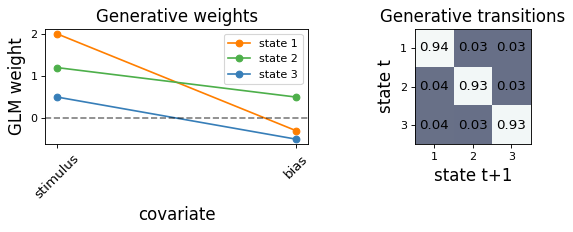

In [5]:
cols = ['#ff7f00', '#4daf4a', '#377eb8']
fig = plt.figure(figsize=(8, 3), dpi=80, facecolor='w', edgecolor='k')

plt.subplot(1, 2, 1)
for k in range(num_states):
    plt.plot(range(input_dim), gen_weights[k], marker='o',
             color=cols[k], lw=1.5, label="state " + str(k + 1))
plt.axhline(y=0, color="k", alpha=0.5, ls="--")
plt.xticks([0, 1], ['stimulus', 'bias'], fontsize=12, rotation=45)
plt.ylabel("GLM weight", fontsize=15)
plt.xlabel("covariate", fontsize=15)
plt.legend()
plt.title("Generative weights", fontsize=15)

plt.subplot(1, 2, 2)
gen_trans_mat = np.exp(gen_log_trans_mat)[0]
plt.imshow(gen_trans_mat, vmin=-0.8, vmax=1, cmap='bone')
for i in range(gen_trans_mat.shape[0]):
    for j in range(gen_trans_mat.shape[1]):
        plt.text(j, i, str(np.around(gen_trans_mat[i, j], decimals=2)),
                 ha="center", va="center", color="k", fontsize=12)
plt.xlim(-0.5, num_states - 0.5)
plt.ylim(num_states - 0.5, -0.5)
plt.xticks(range(num_states), ('1', '2', '3'), fontsize=10)
plt.yticks(range(num_states), ('1', '2', '3'), fontsize=10)
plt.xlabel("state t+1", fontsize=15)
plt.ylabel("state t", fontsize=15)
plt.title("Generative transitions", fontsize=15)
plt.tight_layout()

### 2b. Create binary stimulus sequences and simulate

Each trial's stimulus is either S+ ($s = +\tfrac12$) or S- ($s = -\tfrac12$),
drawn 50/50.  The second covariate is the constant bias term.

In [6]:
num_sess = 40                  # number of sessions
num_trials_per_sess = 300      # trials per session

inpts = np.ones((num_sess, num_trials_per_sess, input_dim))
inpts[:, :, 0] = npr.choice([-0.5, 0.5], (num_sess, num_trials_per_sess))
inpts = list(inpts)

true_latents, true_choices = [], []
for sess in range(num_sess):
    z, y = true_glmhmm.sample(num_trials_per_sess, input=inpts[sess])
    true_latents.append(z)
    true_choices.append(y)

true_ll = true_glmhmm.log_probability(true_choices, inputs=inpts)
print("true ll = " + str(true_ll))

true ll = -7009.697709807548


## 3. Fit a fresh model and recover parameters

In [7]:
new_glmhmm = ssm.HMM(num_states, obs_dim, input_dim,
                     observations="probit_input_driven_obs",
                     transitions="standard")

N_iters = 200
fit_ll = new_glmhmm.fit(true_choices, inputs=inpts, method="em",
                        num_iters=N_iters, tolerance=1e-4)

  0%|          | 0/200 [00:00<?, ?it/s]

Plot EM convergence against the true log-likelihood.

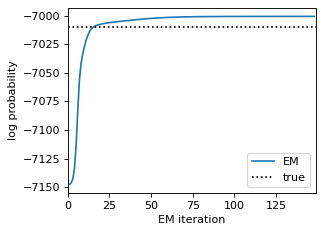

In [8]:
fig = plt.figure(figsize=(4, 3), dpi=80, facecolor='w', edgecolor='k')
plt.plot(fit_ll, label="EM")
plt.plot([0, len(fit_ll)], true_ll * np.ones(2), ':k', label="true")
plt.legend(loc="lower right")
plt.xlabel("EM iteration")
plt.ylabel("log probability")
plt.xlim(0, len(fit_ll))
plt.show()

Align the recovered states to the generative states, then compare weights.

In [9]:
new_glmhmm.permute(find_permutation(
    true_latents[0],
    new_glmhmm.most_likely_states(true_choices[0], input=inpts[0])))

Text(0.5, 1.0, 'Weight recovery')

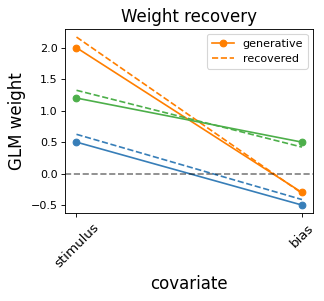

In [10]:
recovered_weights = new_glmhmm.observations.params

fig = plt.figure(figsize=(4, 3), dpi=80, facecolor='w', edgecolor='k')
for k in range(num_states):
    lab_g = "generative" if k == 0 else ""
    lab_r = "recovered" if k == 0 else ""
    plt.plot(range(input_dim), gen_weights[k], marker='o',
             color=cols[k], lw=1.5, label=lab_g)
    plt.plot(range(input_dim), recovered_weights[k], color=cols[k],
             lw=1.5, ls='--', label=lab_r)
plt.axhline(y=0, color="k", alpha=0.5, ls="--")
plt.xticks([0, 1], ['stimulus', 'bias'], fontsize=12, rotation=45)
plt.ylabel("GLM weight", fontsize=15)
plt.xlabel("covariate", fontsize=15)
plt.legend()
plt.title("Weight recovery", fontsize=15)

## 4. Posterior state probabilities and occupancy

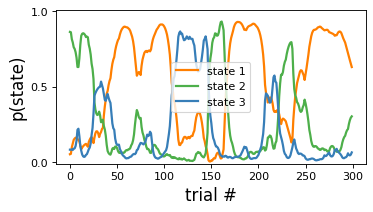

In [11]:
posterior_probs = [new_glmhmm.expected_states(data=y, input=u)[0]
                   for y, u in zip(true_choices, inpts)]

fig = plt.figure(figsize=(5, 2.5), dpi=80, facecolor='w', edgecolor='k')
sess_id = 0
for k in range(num_states):
    plt.plot(posterior_probs[sess_id][:, k], color=cols[k], lw=2,
             label="state " + str(k + 1))
plt.ylim(-0.01, 1.01)
plt.yticks([0, 0.5, 1])
plt.xlabel("trial #", fontsize=15)
plt.ylabel("p(state)", fontsize=15)
plt.legend()

## 5. The SDT readout (what the probit link buys you)

This is the point of the probit class.  With $\pm\tfrac12$ stimulus coding,
each state's recovered weights read off directly as SDT parameters:
$d' = \beta_{\text{stim}}$ and $c = -\beta_{\text{bias}}$.  We verify this
three ways and show they all agree:

1. **Generative** $d'$/$c$ — what we built the model with.
2. **Model** $d'$/$c$ — read off the *recovered* weights via the identity.
3. **Empirical** $d'$/$c$ — computed from the simulated Hit/FA counts.
   We weight each trial by its posterior responsibility
   $p(z_t = k \mid \mathbf{y})$ rather than hard-assigning by argmax: hard
   assignment cherry-picks the cleanest trials into the best-discriminating
   state and inflates its empirical $d'$, whereas the soft (responsibility)
   weighting is exactly the quantity the model's M-step uses.

In [12]:
def empirical_dprime_c(choices, stims, resp_k, eps=1e-3):
    """Posterior-weighted empirical (d', c) for state k.

    resp_k[t] = p(z_t = k | data) is the soft responsibility for state k.
    """
    splus = stims > 0              # S+  (s = +0.5)
    sminus = stims < 0            # S-  (s = -0.5)
    hr = (resp_k[splus] * choices[splus]).sum() / resp_k[splus].sum()
    far = (resp_k[sminus] * choices[sminus]).sum() / resp_k[sminus].sum()
    hr = np.clip(hr, eps, 1 - eps)
    far = np.clip(far, eps, 1 - eps)
    dprime = norm.ppf(hr) - norm.ppf(far)
    crit = -0.5 * (norm.ppf(hr) + norm.ppf(far))
    return dprime, crit


# Concatenate across sessions; keep the soft posterior responsibilities.
all_choices = np.concatenate([y[:, 0] for y in true_choices])
all_stims = np.concatenate([u[:, 0] for u in inpts])
all_resp = np.concatenate(posterior_probs)        # (T_total, K)

gen_dprime = gen_weights[:, 0]            # d' = beta_stim
gen_c = -gen_weights[:, 1]               # c  = -beta_bias
mod_dprime = recovered_weights[:, 0]
mod_c = -recovered_weights[:, 1]
emp_dprime, emp_c = np.zeros(num_states), np.zeros(num_states)
for k in range(num_states):
    emp_dprime[k], emp_c[k] = empirical_dprime_c(
        all_choices, all_stims, all_resp[:, k])

print("        d': generative / model-weights / empirical")
for k in range(num_states):
    print(f"  state {k + 1}:   {gen_dprime[k]:.2f}   /   "
          f"{mod_dprime[k]:.2f}   /   {emp_dprime[k]:.2f}")
print("\n         c: generative / model-weights / empirical")
for k in range(num_states):
    print(f"  state {k + 1}:   {gen_c[k]:+.2f}   /   "
          f"{mod_c[k]:+.2f}   /   {emp_c[k]:+.2f}")

        d': generative / model-weights / empirical
  state 1:   2.00   /   2.17   /   2.17
  state 2:   1.20   /   1.32   /   1.32
  state 3:   0.50   /   0.62   /   0.62

         c: generative / model-weights / empirical
  state 1:   +0.30   /   +0.31   /   +0.31
  state 2:   -0.50   /   -0.42   /   -0.42
  state 3:   +0.50   /   +0.41   /   +0.41


Plot the recovered-weight SDT values against the empirical SDT values.
Points fall on the identity line, confirming that the probit weights are
the SDT parameters.

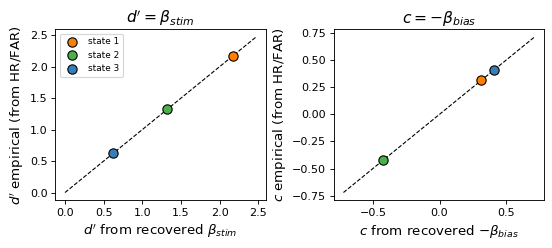

In [13]:
fig = plt.figure(figsize=(7, 3.2), dpi=80, facecolor='w', edgecolor='k')

plt.subplot(1, 2, 1)
for k in range(num_states):
    plt.scatter(mod_dprime[k], emp_dprime[k], color=cols[k], s=70,
                edgecolor='k', zorder=3, label="state " + str(k + 1))
lim = [0, max(mod_dprime.max(), emp_dprime.max()) + 0.3]
plt.plot(lim, lim, 'k--', lw=1)
plt.xlabel(r"$d'$ from recovered $\beta_{stim}$", fontsize=12)
plt.ylabel(r"$d'$ empirical (from HR/FAR)", fontsize=12)
plt.title(r"$d' = \beta_{stim}$", fontsize=14)
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
for k in range(num_states):
    plt.scatter(mod_c[k], emp_c[k], color=cols[k], s=70,
                edgecolor='k', zorder=3)
lo = min(mod_c.min(), emp_c.min()) - 0.3
hi = max(mod_c.max(), emp_c.max()) + 0.3
plt.plot([lo, hi], [lo, hi], 'k--', lw=1)
plt.xlabel(r"$c$ from recovered $-\beta_{bias}$", fontsize=12)
plt.ylabel(r"$c$ empirical (from HR/FAR)", fontsize=12)
plt.title(r"$c = -\beta_{bias}$", fontsize=14)
plt.tight_layout()
plt.show()

## 6. MAP estimation (optional)

As with the logistic GLM-HMM, in the small-data regime you can regularise
the weights with a Gaussian prior via `prior_sigma`, and the transitions
with a sticky Dirichlet prior via `alpha`/`kappa`:

```python
ssm.HMM(num_states, obs_dim, input_dim,
        observations="probit_input_driven_obs",
        observation_kwargs=dict(prior_sigma=2.0),
        transitions="sticky", transition_kwargs=dict(alpha=2.0, kappa=0))
```

The recovered weights still read off as $d'$ and $c$ exactly as above; the
prior simply shrinks them toward zero (toward $d' = 0$, $c = 0$).